### Data Processing

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#### Plot Mean Squared Displacement

All lags:

In [2]:
msd = np.fromfile('./msd_he_ar_3d.bin',dtype=np.float64)[::100]

Text(0.5, 0, 'Lag [Number of Timesteps]')

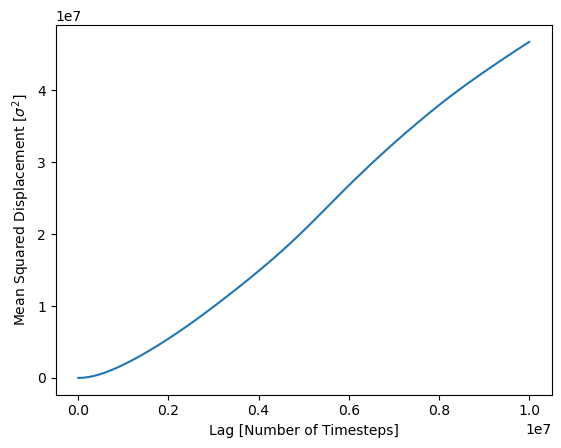

In [3]:
lags = np.arange(1,100*len(msd)+1,100)
plt.plot(lags,msd)
plt.ylabel(r"Mean Squared Displacement [$\sigma^2$]")
plt.xlabel("Lag [Number of Timesteps]")

Text(0.5, 0, 'Lag [Number of Timesteps]')

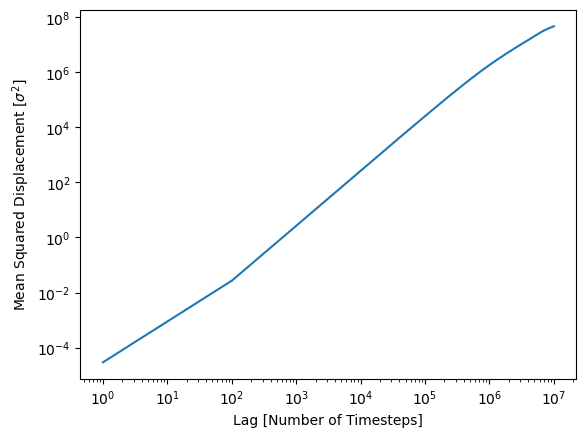

In [4]:
lags = np.arange(1,100*len(msd)+1,100)
plt.loglog(lags,msd)
plt.ylabel(r"Mean Squared Displacement [$\sigma^2$]")
plt.xlabel("Lag [Number of Timesteps]")

- Graph is quadratic for short lags and linear for longer lags
- This is the expected behaviour for a brownian particle with inertia

In [6]:
coeff_linear = np.polyfit(np.log(lags[10000:]),np.log(msd[10000:]),deg=1)[0]
coeff_linear

1.397910630327976

In [7]:
coeff_quadratic = np.polyfit(np.log(lags[:500]),np.log(msd[:500]),deg=1)[0]
coeff_quadratic

1.9543956950407535

#### Estimate Diffusion Coefficient

- Remove initial quadratic part up to around 10000 steps
- Convert quantities to SI units, using the base values for $\epsilon$, $\sigma$ and mass from the Lennard-Jones simulation

In [8]:
linear_lags = lags[10000:]
linear_msd = msd[10000:]

In [9]:
boltzmann = 1.38064852e-23
epsilon = 9.8725*boltzmann
sigma = 252.38*1e-12
mass = 6.64e-27

In [10]:
# timestep = 0.001
# So number of timesteps = 1000*(elapsed time in LJ units) = 1000*sqrt(epsilon/(mass*sigma**2))*(elapsed time in SI units)
linear_lags_SI = linear_lags*np.sqrt(mass*sigma**2/epsilon)/1000
linear_msd_SI = linear_msd*sigma**2

In [11]:
coefs = np.polyfit(linear_lags_SI,linear_msd_SI,deg=1)

Because we only look at the x-component of the trajectory, we divide by 2 (even though the original simulation was 2D):

In [12]:
D_sim = coefs[0]/2
print(D_sim)

9.655437081984367e-05


Estimated value from experiments $\approx 7.3 \times 10^{-5}$

#### Compare with random walk model

- msd random walk 2 uses 7.3 x 10^-5
- msd random walk 2b uses 6.4 x 10^-5

In [13]:
random_walk_msd = np.fromfile('./msd_random_walk_2.bin',dtype=np.float64)[::100]
lags = np.arange(1,100*len(random_walk_msd)+1,100)

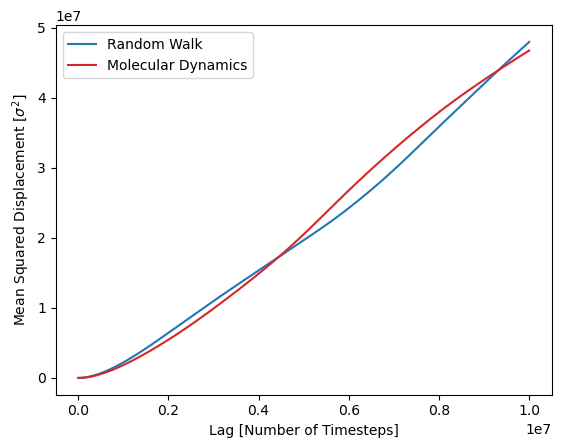

In [15]:
plt.plot(lags,random_walk_msd/sigma**2,label="Random Walk")
plt.plot(lags,msd,color="tab:red",label="Molecular Dynamics")
plt.xlabel("Lag [Number of Timesteps]")
plt.ylabel("Mean Squared Displacement [$\sigma^2$]")
plt.legend()

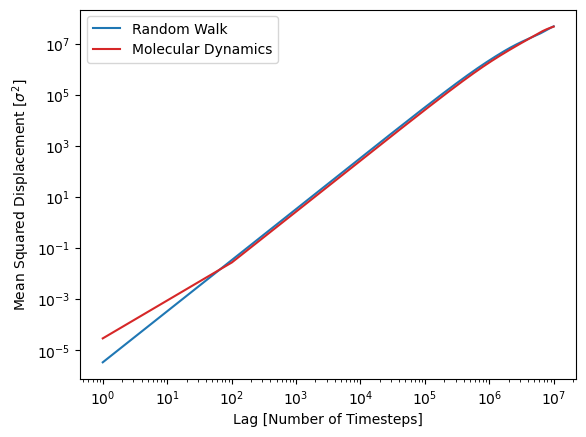

In [16]:
plt.loglog(lags,random_walk_msd/(sigma**2),label="Random Walk")
plt.loglog(lags,msd,color="tab:red",label="Molecular Dynamics")
plt.xlabel("Lag [Number of Timesteps]")
plt.ylabel("Mean Squared Displacement [$\sigma^2$]")
plt.legend()

How many particles?

Reduced density given by:

$\rho^{*} = \rho \frac{\sigma^{\text{dim}}}{m}$

In [21]:
reduced_density = (0.164*(sigma)**3/mass)

In [22]:
reduced_density

0.0003970457729109351

In [23]:
vol = 1000/reduced_density

In [26]:
side_length = vol**(1/3)

In [28]:
side_length/2

68.02833036359573

Time to transition from ballistic to diffusive behaviour:

In [23]:
mass_ar = 39.95*mass/4
D_true = 7.3e-5
gamma = boltzmann*298/D_true
tau = mass_ar/gamma

In [24]:
tau

1.1766528093127885e-09

In [25]:
timestep = 0.001*np.sqrt(mass*sigma**2/epsilon)

In [26]:
tau/timestep

667981.5964384835

So should take around 670000 timesteps to transition from ballistic to diffusive behaviour